# Raghavan et al. 2021 — PDAC (Seq-Well)
## 03 · Developmental signatures → Gate 2

Score Gast/pSom/Crest with the union control pool; read geography off graph-smoothed scores but **show raw scores** in the deliverable UMAPs. Gate 2 tests whether the embryonic module pattern appears.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer','vertebrate','CCCA','Claude',cat,name)
pth_fig = os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude',cat,name)
pth_cb  = os.path.join(pth_fig,'colorbars'); os.makedirs(pth_cb, exist_ok=True)
pth_feat = os.path.join(pth_data,'features','biomart')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out,'manifold.h5ad'))
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('cells:', adata.shape[0])

Gast: 73/81 genes present
pSom: 85/98 genes present
Crest: 103/104 genes present
cells: 7830


### Gate 2 — module geography
Gast & pSom co-vary and both oppose Crest; Crest is the inverse **terminal** gradient (peaks at high pseudotime).

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if >0.5)')
print('global module means (raw):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('Crest enriches the terminus (away from Gast/pSom), NOT the Gast arm -> no inversion flag.')
print('GATE 2 = GO (non-branching): single Gast/pSom -> Crest gradient, Crest inverse & terminal.')
print('GATE 3 = NA: no bifurcation.')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.25
  Crest_sm vs Gast_sm: r = -0.75
  Crest_sm vs pSom_sm: r = -0.65
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.403
  pSom_sm: rho = -0.621
  Crest_sm: rho = +0.515
Neural-crest-high decile mean pseudotime = 0.56 (terminal if >0.5)
global module means (raw): {'Gast': -0.0112, 'pSom': 0.0718, 'Crest': -0.0236}
Crest enriches the terminus (away from Gast/pSom), NOT the Gast arm -> no inversion flag.
GATE 2 = GO (non-branching): single Gast/pSom -> Crest gradient, Crest inverse & terminal.
GATE 3 = NA: no bifurcation.


### Signature UMAPs (raw scores) + colorbars — house `(3.5,1.5)` aspect, shared orientation

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


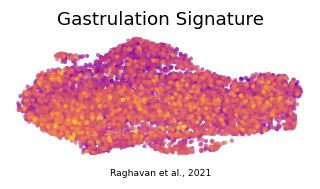

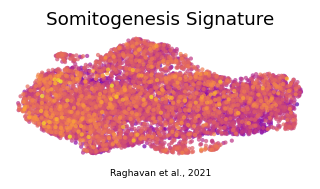

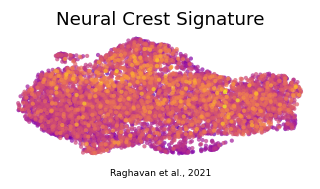

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight'); plt.show()
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight'); plt.close(fcb)
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [6]:
adata.write(os.path.join(pth_out,'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (7830, 16784)
